# SolarCheck AI · Entrenamiento y evaluación

**Certamen: Clasificación de imágenes con modelos preentrenados e IA generativa**

Se estudian **seis condiciones visuales de paneles fotovoltaicos** para apoyar una inspección preventiva. Se compara CLIP zero-shot (línea base) frente a EfficientNet-B0 de `timm`, ajustado con transferencia de aprendizaje.

> **Nota de reproducibilidad:** las salidas de las celdas originales son resultados genuinos de la ejecución adjuntada por el grupo. Las nuevas celdas explicativas no han sido ejecutadas. Para obtener los pesos faltantes hay que ejecutar el notebook en Google Colab de principio a fin; las métricas pueden variar ligeramente entre corridas. Nunca se deben inventar resultados ni sustituir el modelo por pesos aleatorios.

## 0. Preparar el entorno

En Colab, seleccionar **Entorno de ejecución → Cambiar tipo de entorno → GPU** cuando esté disponible.

In [ ]:
# Ejecutar en Google Colab (las demás dependencias científicas suelen venir instaladas).
%pip -q install kagglehub timm transformers scikit-learn

## 1. Datos y ficha de procedencia

| Campo | Información registrada en el notebook original |
|---|---|
| Dataset | Solar Panel Images: Clean and Faulty Images |
| Autor de Kaggle | Afroz (`pythonafroz`) |
| Enlace | https://www.kaggle.com/datasets/pythonafroz/solar-panel-images |
| Cómo se obtuvo | Descarga programática con `kagglehub` desde Kaggle; no se documenta la metodología original de captación de imágenes |
| Licencia | **No especificada / Unknown** en el registro del proyecto: verificar derechos de uso antes de redistribuir |
| Clases y tamaños | Clean (193), Bird-drop (191), Dusty (190), Snow-Covered (123), Electrical-damage (103), Physical-Damage (69) |
| Total analizado | 869 imágenes (sin incluir 16 de `New`) |
| Problema | Clasificación multiclase para priorizar limpieza y revisión técnica de paneles solares |

**Desbalance y limitaciones.** La clase menor tiene 69 imágenes y la mayor 193. Se usan pesos en la función de pérdida; no garantizan eliminar el sesgo. La procedencia es una única colección, hay pocos ejemplos de daño físico, no se dispone de una validación de campo ni información sobre condiciones de cámara, regiones o representatividad de instalaciones reales. La licencia no verificada restringe la redistribución del dataset y de las fotografías de ejemplo.


In [ ]:
# Descargar el dataset desde Kaggle
import kagglehub, os
path = kagglehub.dataset_download("pythonafroz/solar-panel-images")
print("Ruta:", path)

# Contar imágenes por clase
for root, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if imgs:
        print(f"{os.path.basename(root):25s} {len(imgs)}")

100%|██████████| 305M/305M [00:02<00:00, 113MB/s]

Extracting files...


Ruta: /root/.cache/kagglehub/datasets/pythonafroz/solar-panel-images/versions/2
Bird-drop                 191
New                       16
Dusty                     190
Physical-Damage           69
Electrical-damage         103
Clean                     193
Snow-Covered              123


Excluimos la clase New por tener solo 16 imágenes; trabajamos con 6 clases (869 imágenes) y el desbalance lo compensamos en el entrenamiento.

In [ ]:
# División estratificada 70% train / 15% val / 15% test
import os, shutil, random
from sklearn.model_selection import train_test_split

SRC = path                       # ruta del dataset descargado
DST = "/content/data"            # carpeta de trabajo
EXCLUIR = {"New"}                # clase descartada (solo 16 imágenes)
random.seed(42)

# 1) Recolectar imágenes por clase
imgs, labels = [], []
for root, dirs, files in os.walk(SRC):
    clase = os.path.basename(root)
    if clase in EXCLUIR:
        continue
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            imgs.append(os.path.join(root, f))
            labels.append(clase)

# 2) Separar manteniendo la proporción de cada clase (stratify)
X_train, X_tmp, y_train, y_tmp = train_test_split(
    imgs, labels, test_size=0.30, stratify=labels, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

# Limpiar carpetas previas: evita que una segunda ejecución mezcle imágenes
# de particiones antiguas (fuga accidental de datos).
if os.path.isdir(DST):
    shutil.rmtree(DST)

# 3) Copiar a carpetas data/train|val|test/<clase>/
for split, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    for src, c in zip(X, y):
        os.makedirs(f"{DST}/{split}/{c}", exist_ok=True)
        shutil.copy(src, f"{DST}/{split}/{c}/")

# 4) Tabla resumen para la ficha
import pandas as pd
resumen = pd.DataFrame({s: pd.Series(yy).value_counts()
                        for s, yy in [("train", y_train), ("val", y_val), ("test", y_test)]})
resumen["total"] = resumen.sum(axis=1)
print(resumen)

                   train  val  test  total
Bird-drop            134   28    29    191
Clean                135   29    29    193
Dusty                133   28    29    190
Electrical-damage     72   16    15    103
Physical-Damage       48   11    10     69
Snow-Covered          86   18    19    123


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Accuracy:          0.481
Balanced accuracy: 0.514
                   precision    recall  f1-score   support

        Bird-drop      0.318     0.241     0.275        29
            Clean      0.532     0.862     0.658        29
            Dusty      0.200     0.034     0.059        29
Electrical-damage      0.240     0.400     0.300        15
  Physical-Damage      0.545     0.600     0.571        10
     Snow-Covered      0.857     0.947     0.900        19

         accuracy                          0.481       131
        macro avg      0.449     0.514     0.460       131
     weighted avg      0.426     0.481     0.428       131



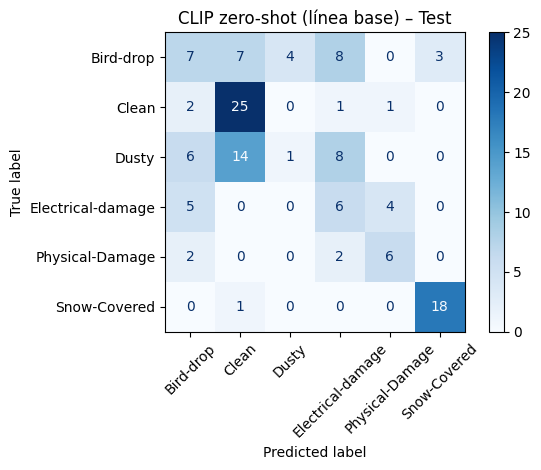

In [ ]:
# Línea base: CLIP zero-shot sobre el conjunto de TEST
import torch, glob, os
import numpy as np
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

CLASES = sorted(os.listdir("/content/data/test"))
# Descripción en texto de cada clase (CLIP compara la imagen con estas frases)
PROMPTS = {
    "Bird-drop":         "a photo of a solar panel with bird droppings on it",
    "Clean":             "a photo of a clean solar panel",
    "Dusty":             "a photo of a dusty dirty solar panel",
    "Electrical-damage": "a photo of a solar panel with burn marks or electrical damage",
    "Physical-Damage":   "a photo of a solar panel with cracked or broken glass",
    "Snow-Covered":      "a photo of a solar panel covered with snow",
}
textos = [PROMPTS[c] for c in CLASES]

y_true, y_pred = [], []
for i, c in enumerate(CLASES):
    for f in glob.glob(f"/content/data/test/{c}/*"):
        img = Image.open(f).convert("RGB")
        inputs = proc(text=textos, images=img, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            probs = clip(**inputs).logits_per_image.softmax(dim=1)
        y_true.append(i)
        y_pred.append(probs.argmax().item())

print(f"Accuracy:          {accuracy_score(y_true, y_pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.3f}")
print(classification_report(y_true, y_pred, target_names=CLASES, digits=3))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASES,
                                        xticks_rotation=45, cmap="Blues")
plt.title("CLIP zero-shot (línea base) – Test")
plt.tight_layout(); plt.show()

CLIP sin entrenar no distingue bien las suciedades sutiles, y eso justifica hacer fine-tuning.


Pesos por clase: {'Bird-drop': np.float32(0.76), 'Clean': np.float32(0.75), 'Dusty': np.float32(0.76), 'Electrical-damage': np.float32(1.41), 'Physical-Damage': np.float32(2.11), 'Snow-Covered': np.float32(1.18)}


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Época  1 | loss train 1.949 | bal-acc val 0.652
Época  2 | loss train 0.425 | bal-acc val 0.679
Época  3 | loss train 0.226 | bal-acc val 0.772
Época  4 | loss train 0.209 | bal-acc val 0.803
Época  5 | loss train 0.084 | bal-acc val 0.758
Época  6 | loss train 0.091 | bal-acc val 0.780
Época  7 | loss train 0.061 | bal-acc val 0.780
Época  8 | loss train 0.067 | bal-acc val 0.768
Época  9 | loss train 0.057 | bal-acc val 0.773
Época 10 | loss train 0.033 | bal-acc val 0.755
Época 11 | loss train 0.046 | bal-acc val 0.752
Época 12 | loss train 0.045 | bal-acc val 0.758
Época 13 | loss train 0.029 | bal-acc val 0.758
Época 14 | loss train 0.020 | bal-acc val 0.749
Época 15 | loss train 0.030 | bal-acc val 0.758

TEST  Accuracy: 0.740 | Balanced accuracy: 0.768
                   precision    recall  f1-score   support

        Bird-drop      0.778     0.724     0.750        29
            Clean      0.706     0.828     0.762        29
            Dusty      0.737     0.483     0.583    

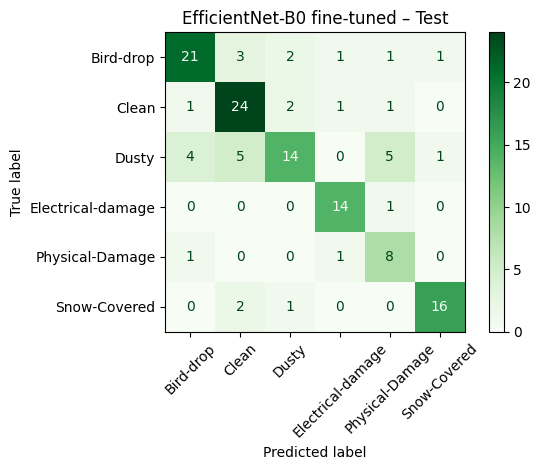

Guardado en /content/modelo/


In [ ]:
# Fine-tuning de EfficientNet-B0 (timm) con pesos por clase y data augmentation
!pip -q install timm
import torch, timm, json, os, copy
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)

# 1) Transformaciones: augmentation solo en train
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tf_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),   # suave: no borrar el polvo
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_eval = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

ds_train = datasets.ImageFolder("/content/data/train", tf_train)
ds_val   = datasets.ImageFolder("/content/data/val",   tf_eval)
ds_test  = datasets.ImageFolder("/content/data/test",  tf_eval)
CLASES = ds_train.classes
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True,  num_workers=2)
dl_val   = DataLoader(ds_val,   batch_size=32, shuffle=False, num_workers=2)
dl_test  = DataLoader(ds_test,  batch_size=32, shuffle=False, num_workers=2)

# 2) Pesos por clase (compensan el desbalance: clases chicas pesan más)
conteo = np.bincount(ds_train.targets)
pesos = torch.tensor(len(ds_train) / (len(CLASES) * conteo), dtype=torch.float).to(device)
print("Pesos por clase:", dict(zip(CLASES, pesos.cpu().numpy().round(2))))

# 3) Modelo preentrenado en ImageNet, con nueva capa final de 6 clases
model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(CLASES)).to(device)
criterio = nn.CrossEntropyLoss(weight=pesos)
optim = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
EPOCHS = 15
sched = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=EPOCHS)

def predecir(dl):
    model.eval(); yt, yp = [], []
    with torch.no_grad():
        for x, y in dl:
            yp += model(x.to(device)).argmax(1).cpu().tolist(); yt += y.tolist()
    return yt, yp

# 4) Entrenamiento: se guarda el mejor modelo según balanced accuracy en VALIDACIÓN
mejor, mejor_estado, hist = 0, None, []
for ep in range(EPOCHS):
    model.train(); perdida = 0
    for x, y in dl_train:
        x, y = x.to(device), y.to(device)
        optim.zero_grad(); loss = criterio(model(x), y); loss.backward(); optim.step()
        perdida += loss.item() * len(y)
    sched.step()
    yt, yp = predecir(dl_val)
    bacc = balanced_accuracy_score(yt, yp)
    hist.append((perdida / len(ds_train), bacc))
    print(f"Época {ep+1:2d} | loss train {hist[-1][0]:.3f} | bal-acc val {bacc:.3f}")
    if bacc > mejor:
        mejor, mejor_estado = bacc, copy.deepcopy(model.state_dict())

model.load_state_dict(mejor_estado)

# 5) Evaluación final en TEST (misma métrica que CLIP)
yt, yp = predecir(dl_test)
print(f"\nTEST  Accuracy: {accuracy_score(yt, yp):.3f} | Balanced accuracy: {balanced_accuracy_score(yt, yp):.3f}")
print(classification_report(yt, yp, target_names=CLASES, digits=3))
ConfusionMatrixDisplay.from_predictions(yt, yp, display_labels=CLASES, xticks_rotation=45, cmap="Greens")
plt.title("EfficientNet-B0 fine-tuned – Test"); plt.tight_layout(); plt.show()

# 6) Exportar el modelo para la app
os.makedirs("/content/modelo", exist_ok=True)
torch.save(model.state_dict(), "/content/modelo/modelo.pt")
with open("/content/modelo/clases.json", "w", encoding="utf-8") as archivo:
    json.dump({"modelo": "efficientnet_b0", "clases": CLASES,
               "test_total": len(yt),
               "test_accuracy": round(accuracy_score(yt, yp), 3),
               "test_balanced_accuracy": round(balanced_accuracy_score(yt, yp), 3)},
              archivo, indent=2, ensure_ascii=False)
print("Guardado en /content/modelo/")

## 4. Resultados de prueba observados (ejecución original)

| Métrica en TEST | CLIP zero-shot | EfficientNet-B0 fine-tuned |
|---|---:|---:|
| Accuracy | 0,481 | **0,740** |
| Balanced accuracy | 0,514 | **0,768** |
| Recall de `Dusty` | 0,034 | **0,483** |
| `Dusty` confundido con `Clean` | 14/29 | **5/29** |

La **mejora de 25,9 puntos porcentuales en accuracy** y la recuperación superior del conjunto de clases respaldan la elección de EfficientNet-B0. El resultado no demuestra que sea suficientemente fiable para decisiones operativas reales.

Los valores de esta tabla corresponden a la ejecución original conservada en las salidas, no a una nueva corrida.


                   CLIP zero-shot  EfficientNet-B0
Accuracy                    0.481            0.740
Balanced accuracy           0.514            0.768


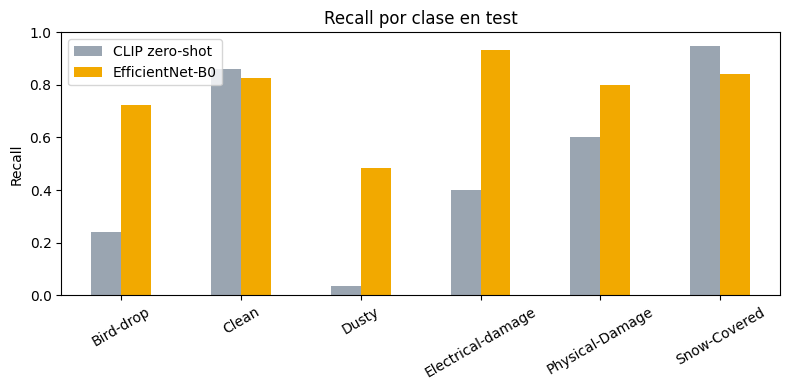

In [ ]:
# Comparación CLIP zero-shot vs EfficientNet-B0 en el mismo conjunto de TEST
import pandas as pd
from sklearn.metrics import recall_score

comp = pd.DataFrame({
    "CLIP zero-shot":  [accuracy_score(y_true, y_pred), balanced_accuracy_score(y_true, y_pred)],
    "EfficientNet-B0": [accuracy_score(yt, yp),         balanced_accuracy_score(yt, yp)],
}, index=["Accuracy", "Balanced accuracy"]).round(3)
print(comp)

# Recall por clase: ¿qué tan bien detecta cada condición?
rec = pd.DataFrame({
    "CLIP zero-shot":  recall_score(y_true, y_pred, average=None),
    "EfficientNet-B0": recall_score(yt, yp, average=None),
}, index=CLASES)
rec.plot(kind="bar", figsize=(8, 4), color=["#9aa5b1", "#f2a900"])
plt.title("Recall por clase en test"); plt.ylabel("Recall"); plt.ylim(0, 1)
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig("/content/modelo/comparacion.png", dpi=150); plt.show()

In [ ]:
# Empaquetar modelo + ejemplos en un zip y descargarlo
import shutil, os, glob
from google.colab import files

# 1 imagen de ejemplo por clase, tomada del conjunto de test
os.makedirs("/content/solarcheck/ejemplos", exist_ok=True)
for c in CLASES:
    primera = sorted(glob.glob(f"/content/data/test/{c}/*"))[0]
    ext = os.path.splitext(primera)[1]
    shutil.copy(primera, f"/content/solarcheck/ejemplos/{c}{ext}")

# Carpeta del modelo (modelo.pt, clases.json, comparacion.png)
shutil.copytree("/content/modelo", "/content/solarcheck/modelo", dirs_exist_ok=True)

# Comprimir y descargar
shutil.make_archive("/content/solarcheck", "zip", "/content/solarcheck")
files.download("/content/solarcheck.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Interpretación del error y seguridad

**Error operativo relevante:** un panel con polvo que se clasifica como limpio puede quedar fuera del plan de limpieza preventiva y perder eficiencia; en el conjunto de prueba el modelo final clasificó como `Clean` **5 de los 29** paneles `Dusty`. La clase `Dusty` obtuvo 48,3% de recall, por lo que más de la mitad de las imágenes de esa condición no se identificaron correctamente.

**Error de mayor gravedad potencial:** confundir un panel con **posible daño eléctrico** con una condición rutinaria podría retrasar una inspección y exponer a personas a peligros si se toman decisiones solo con el sistema. No asignamos un costo económico numérico, porque no contamos con datos de incidentes, precios de limpieza o reparaciones. Los errores de seguridad deben tener revisión humana obligatoria.

**Conclusión:** EfficientNet-B0 se elige por su desempeño relativo frente a CLIP en este test, no porque tenga precisión suficiente para certificar seguridad. La 'confianza' del softmax no es una probabilidad calibrada del estado real; tampoco es el mismo concepto que el accuracy global de prueba. No usar el test para ajustar repetidamente hiperparámetros; reservarlo para evaluación final.

## 6. Llevar los pesos a la aplicación

1. Ejecutar las celdas hasta `Guardado en /content/modelo/`.
2. Ejecutar la celda que descarga `solarcheck.zip`; contiene **los pesos reales** y hasta seis fotografías de ejemplo tomadas del test.
3. En tu computador, desde la carpeta del proyecto: `python integrar_exportacion.py ruta/al/solarcheck.zip`.
4. Validar `python verificar_proyecto.py`; después `streamlit run app.py`.
5. Antes de publicar, **revisar la licencia del dataset**: no subir fotografías de ejemplo sin permiso de redistribución. Las salidas del notebook originales aquí conservadas no sustituyen volver a ejecutar el código si cambias el entrenamiento.


In [ ]:
# Inspección adicional opcional (ejecutar después del entrenamiento).
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
print('Orden de clases:', CLASES)
print('Matriz de confusión final:\n', confusion_matrix(yt, yp, labels=list(range(len(CLASES)))))
print('Support test por clase:', dict(zip(CLASES, np.bincount(yt))))
assert len(yt) == len(yp) == len(ds_test)
assert len(CLASES) == 6


## Actualización de la exportación del 19/10/2026
El archivo `solarcheck.zip` entregado después de este notebook contiene pesos `modelo.pt` y un `modelo/clases.json` que registra accuracy **0,878** y balanced accuracy **0,878**. Las salidas visibles anteriores de este notebook corresponden a otra ejecución (accuracy 0,740). **No se reemplazaron artificialmente los resultados de las celdas.** Para entregar la evidencia de la nueva ejecución, ejecutar **todas** las celdas en Colab con ese entrenamiento y guardar el cuaderno actualizado con las nuevas salidas. La app emplea los pesos reales del ZIP más reciente y sus metadatos de prueba.
